### Identification EKF 4R2C — 16 logements (BEopt)
Reconstruction du code d'identification 4R2C à partir du code 5R2C (`code_1.docx`, conservé intact).
**Chaîne** : EKF à état augmenté (log-paramètres, ZOH exact) → raffinement erreur de sortie (OE, multi-départ) → identifiabilité (Fisher) → simulation libre sur fenêtres jamais vues.
Placer les 32 fichiers `<apt>_chauffage_<S>m2.csv` / `<apt>_roue_libre_<S>m2.csv` dans `CONFIG["dossier_donnees"]` (cellule 1).

In [ ]:

# =====================================================================================================
#  IDENTIFICATION DES PARAMÈTRES THERMIQUES 4R2C PAR FILTRE DE KALMAN ÉTENDU (EKF) — version ekf4r2c v1
#  Projet « flexibilité thermique » — immeuble multilogement de 16 logements (101…404)
#
#  Point de départ : le code 5R2C de Daniel (code_1.docx), conservé intact. Ce fichier est NOUVEAU.
#  Différences de fond par rapport au 5R2C :
#    1) Couplage VERTICAL supprimé (plus de T_top / T_bot ni de R_vert) : hypothèse abandonnée en 4R2C.
#    2) Structure IDENTIQUE à celle du simulateur MPC v1d (sans l'ETS) → les paramètres identifiés
#       s'injectent directement dans parametres_thermiques1.csv (colonnes Apt;Ri;Re;Ci;Cm;Radj;Rcoul).
#    3) Discrétisation EXACTE par bloqueur d'ordre zéro (ZOH, exponentielle matricielle) au lieu
#       d'Euler explicite (Euler à Δt = 3600 s est proche de la limite de stabilité pour Ri·Ci ≈ 2 h).
#    4) Paramètres estimés en LOGARITHME (positivité garantie, covariances homogènes malgré des
#       ordres de grandeur de 1e-3 K/W à 1e7 J/K) — plus besoin de « clip » arbitraire.
#    5) La validation se fait en SIMULATION LIBRE (boucle ouverte, sans correction par la mesure) sur
#       les fichiers « roue libre » : dans le code 5R2C, le RMSE était calculé sur l'estimation FILTRÉE
#       de l'EKF (corrigée à chaque pas par la mesure) → RMSE artificiellement faible et non probant.
#    6) Aucune donnée de validation n'entre dans l'estimation (le 5R2C concaténait calibrage + validation).
#    7) Suppression du décalage np.roll(…, 3 h) : l'alignement temporel est traité par une convention
#       explicite (CONFIG["convention_pas"]) testée objectivement.
#    8) Étape 2 « erreur de sortie » (OE, moindres carrés sur la simulation libre) initialisée par l'EKF,
#       puis analyse d'IDENTIFIABILITÉ (matrice d'information de Fisher, écarts-types, corrélations).
#
#  Modèle 4R2C (nœuds : air intérieur T_in de capacité Ci ; masse d'enveloppe T_m de capacité Cm) :
#     Ci·dT_in/dt = (T_m − T_in)/Ri + (T_cor − T_in)/Rcoul + (T_vois − T_in)/Radj
#                   + Q_ch + Q_int + A_s·I_sol + Q_0
#     Cm·dT_m/dt  = (T_in − T_m)/Ri + (T_ext − T_m)/Re
#  avec T_cor = α·T_ext + (1 − α)·moyenne(T_in de l'étage)  (même définition que le simulateur)
#       T_vois = température du logement mitoyen du même palier (101↔102, 103↔104, …)
#  4 résistances (Ri, Re, Radj, Rcoul) + 2 capacités (Ci, Cm) = « 4R2C ».
#  A_s (m²) = surface d'ouverture solaire équivalente (vitrage × SHGC × facteur d'orientation),
#  paramètre auxiliaire identifié lui aussi (le 5R2C le fixait à 12,5·0,6 ou 9,2·0,6 m²).
#  Q_0 (W) = apports internes NON MESURÉS (occupants, appareils, éclairage), supposés constants.
#  Justification : le bilan journalier des deux scénarios (chauffage + roue libre) exige ≈ 220–360 W
#  d'apport constant par logement ; la colonne Q_int des fichiers BEopt a une moyenne ≈ 0 W (échanges
#  nets ±), elle ne représente donc pas les gains internes. Sans Q_0, les pertes sont surestimées et la
#  validation en roue libre dérive de −7 à −13 °C. Dans le simulateur MPC, Q_0 est remplacé par le
#  profil d'occupation richardsonpy (flux_occ_apts), ce qui est cohérent.
# =====================================================================================================

In [1]:
%pip install numpy pandas matplotlib scipy openpyxl seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# %% Cellule 1/9 — Imports et CONFIGURATION (tout ce qui se règle est ici, commenté)
import os, glob, re, time, warnings
import numpy as np
import pandas as pd
from scipy.linalg import expm
from scipy.optimize import least_squares
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)

CONFIG = dict(
    # --- Données ---
    dossier_donnees=".",          # dossier contenant les fichiers <apt>_chauffage_<S>m2.csv et <apt>_roue_libre_<S>m2.csv
    dossier_sorties="sorties_ekf4r2c",
    liste_apts=[101, 102, 103, 104, 201, 202, 203, 204, 301, 302, 303, 304, 401, 402, 403, 404],
    dt=3600.0,                    # pas des fichiers BEopt (s) : 1 h
    N_max=None,                   # None = toute la longueur commune (732 h, limitée par 203) ; ex. 504 pour 21 jours
    # --- Hypothèses de couplage (cohérentes avec le simulateur MPC v1d) ---
    alpha_coul=0.8,               # poids de T_ext dans T_cor (simulateur v1d : 0,8 ; ancien 5R2C : 0,4 → à trancher)
    # --- Convention temporelle des fichiers BEopt (horodatage au milieu de l'heure : 0,5 ; 1,5 ; …) ---
    #  "concomitante" : T_int[k] = état à la FIN de l'heure k, après application des entrées de l'heure k
    #                   (cohérent avec le saut de T_int dans la même ligne que Q_ch dans les fichiers)
    #  "retardee"     : T_int[k+1] = f(T_int[k], entrées[k]) (convention du code 5R2C)
    convention_pas="concomitante",
    # --- Valeurs a priori (initialisation EKF) : ordres de grandeur physiques, par m² de plancher ---
    prior=dict(Ri=7.0e-4 * 72,    # K/W × m²  (h_i ≈ 7,7 W/m²K sur ≈ 2,5 m² de paroi par m² de plancher) → divisé par S
               Re=0.020 * 72,     # K/W × m²  (UA enveloppe ≈ 50 W/K pour 72 m²)
               Radj=0.08,         # K/W       (mur mitoyen ≈ 25 m² à U ≈ 0,5 W/m²K) — valeur initiale du 5R2C
               Rcoul=0.05,        # K/W       (cloison + porte vers le corridor) — valeur initiale du 5R2C
               Ci=6.0e4,          # J/K par m² (air + mobilier ≈ 20 × capacité de l'air)
               Cm=4.0e5,          # J/K par m² (masse d'enveloppe active)
               As=3.0,            # m²        (ouverture solaire équivalente)
               Q0=300.0,
               Rsol=0.05),        # K/W       (dalle sur sol, RDC ; ≈ 72 m² à U_eff ≈ 0,3 W/m²K)         # W         (apports internes non mesurés, pour 72 m² ; mis à l'échelle par S)
    incert_prior=np.log(3.0),     # écart-type a priori de log(θ) : facteur 3 de part et d'autre
    # --- Paramètres FIXÉS (non identifiés) : {nom: valeur} ; les valeurs de « prior » sont utilisées si None ---
    #  Diagnostic (voir rapport) : les fichiers BEopt sont des simulations INDÉPENDANTES par logement (parois
    #  mitoyennes adiabatiques) ; T_vois et T_cor ne sont donc pas des causes physiques de T_in dans ces données.
    #  Laissés libres, Radj et Rcoul « copient » la sortie du voisin (Radj → 1e-3 K/W, non physique).
    #  Variante retenue par défaut : Radj et Rcoul fixés aux valeurs géométriques (U·A des parois).
    params_fixes={"Radj": None, "Rcoul": None},
    bornes_facteur=50.0,          # bornes de l'étape OE : prior / 50 … prior × 50
    # --- Bruits de l'EKF ---
    sigma_mes=0.10,               # écart-type de la mesure T_in (°C) : moyenne horaire BEopt + erreur de structure
    sigma_proc=(0.05, 0.02),      # bruit de processus sur (T_in, T_m) par pas (°C)
    sigma_marche_param=1e-3,      # marche aléatoire de log(θ) par pas (≈ 0,1 %/h) : permet un lent ajustement
    n_passes_ekf=2,               # nombre de passes EKF successives sur les données de calibrage (2ᵉ passe = démarrage chaud)
    # --- Protocole de calibrage / validation ---
    #  "chauffage" : protocole initial — calibrage sur tout le fichier chauffage, validation sur tout le fichier
    #                roue libre. Limite démontrée : Re et Q_0 sont confondus (|ρ| ≈ 0,97) car T_in reste
    #                dans 18–25 °C ; l'extrapolation en roue libre est biaisée (jusqu'à −7 °C au RDC).
    #  "conjoint"  : identification MULTI-EXPÉRIENCES — calibrage simultané sur les N_cal premières heures des
    #                DEUX scénarios ; test sur les heures restantes des deux scénarios (jamais vues).
    #                Les deux régimes (chauffé / non chauffé) séparent pertes (UA) et apports gratuits (Q_0).
    protocole="conjoint",
    # --- Nœud SOL (rez-de-chaussée seulement) : conductance 1/Rsol entre l'air et un sol à T_sol constante ---
    #  Sans ce terme, le RDC (101–104) surestime T_in quand T_ext remonte (la dalle suit le sol, pas l'air).
    noeud_sol_rdc=False,          # True = active Rsol au RDC (essai : gain marginal → désactivé ; voir rapport)
    T_sol=8.0,                    # °C, température du sol sous dalle en hiver (hypothèse ; ≈ moyenne annuelle de l'air à Trois-Rivières)
    N_cal=504,                    # heures de calibrage en mode conjoint (21 jours, comme NB_HEURES_MAX du 5R2C)
    # --- Évaluation ---
    horizon_pred_h=6,             # erreur de prédiction à h pas (Tableau I du manuscrit : 6 h)
    seuil_corr=0.95,              # |corrélation| au-delà de laquelle deux paramètres sont jugés non séparables
    seuil_ecart_rel=0.5,          # écart-type relatif au-delà duquel un paramètre est jugé mal identifié
    langue_figures="fr",          # "fr" ou "en"
)

NOMS_THETA = ["Ri", "Re", "Radj", "Rcoul", "Ci", "Cm", "As", "Q0", "Rsol"]
R_INACTIF = 1e6                   # résistance « infinie » (K/W) : désactive un couplage (ex. Rsol aux étages)
FIXES_COURANTS = {}               # paramètres fixés pour le logement en cours (rempli par identifier_logement)   # ordre du vecteur de paramètres θ
N_THETA = len(NOMS_THETA)

def indices_libres():
    """Indices des paramètres réellement estimés (ceux qui ne sont pas dans CONFIG["params_fixes"])."""
    return [i for i, n in enumerate(NOMS_THETA) if n not in FIXES_COURANTS]

def fixer_pour(apt):
    """Paramètres fixés du logement : ceux de CONFIG + Rsol inactif aux étages (ou partout si noeud_sol_rdc=False)."""
    global FIXES_COURANTS
    FIXES_COURANTS = dict(CONFIG["params_fixes"])
    if apt >= 200 or not CONFIG["noeud_sol_rdc"]: FIXES_COURANTS["Rsol"] = R_INACTIF
print(" Cellule 1/9 : configuration chargée.")

 Cellule 1/9 : configuration chargée.


In [3]:
# %% Cellule 2/9 — Conversions d'unités impériales (BEopt) et chargement des fichiers
def f_vers_c(T_F):
    """°F → °C."""
    return (np.asarray(T_F, float) - 32.0) * 5.0 / 9.0

def btu_vers_w(Q_btu_par_h):
    """Énergie horaire en Btu (= puissance moyenne en Btu/h) → W. 1 Btu/h = 0,29307107 W."""
    return np.asarray(Q_btu_par_h, float) * 0.29307107

def flux_us_vers_si(I_us):
    """Éclairement solaire Btu/(h·ft²) → W/m² (facteur 3,15459). Max des fichiers 275 → 868 W/m² : plausible."""
    return np.asarray(I_us, float) * 3.15459

def surface(apt):
    """Surface de plancher : 72 m² au rez-de-chaussée (1xx), 56 m² aux étages."""
    return 72 if apt < 200 else 56

def trouver_fichier(apt, scenario):
    """Cherche <apt>_<scenario>_<S>m2.csv dans le dossier, y compris avec un préfixe ajouté au téléversement
    (ex. « 169407f8-101_chauffage_72m2.csv »). Retourne None si absent."""
    motif = os.path.join(CONFIG["dossier_donnees"], f"*{apt}_{scenario}_{surface(apt)}m2.csv")
    cand = [f for f in glob.glob(motif) if re.search(rf"(^|[-_/]){apt}_{scenario}_", os.path.basename(f))
            or os.path.basename(f).startswith(f"{apt}_")]
    return sorted(cand)[0] if cand else None

def lire_fichier_beopt(chemin):
    """Lit un fichier BEopt (séparateur ;) et convertit en SI.
    Colonnes attendues : Timps(h);T_ext_F;Q_ch_Btu;Q_int_Btu;I_sol_US;T_int_F
    Retour : DataFrame [t_h, T_ext, Q_ch, Q_int, I_sol, T_in] en (h, °C, W, W, W/m², °C)."""
    d = pd.read_csv(chemin, sep=";")
    d.columns = [c.strip() for c in d.columns]
    col = lambda cle: next(c for c in d.columns if cle.lower() in c.lower())   # lève StopIteration si absente (pas de repli silencieux)
    num = lambda c: pd.to_numeric(d[col(c)], errors="coerce").interpolate(limit_direction="both").values
    return pd.DataFrame(dict(t_h=num("timps"), T_ext=f_vers_c(num("t_ext")), Q_ch=btu_vers_w(num("q_ch")),
                             Q_int=btu_vers_w(num("q_int")), I_sol=flux_us_vers_si(num("i_sol")),
                             T_in=f_vers_c(num("t_int"))))

def voisin_mitoyen(apt):
    """Logement mitoyen du même palier : 101↔102, 103↔104 (même règle que le simulateur v1d)."""
    return apt + 1 if apt % 2 else apt - 1

def construire_jeu(scenario):
    """Charge les 16 logements d'un scénario ("chauffage" ou "roue_libre") et ajoute à chacun :
       T_cor  = α·T_ext + (1 − α)·moyenne des T_in de l'étage (même scénario) ;
       T_vois = T_in du logement mitoyen (même scénario).
    Toutes les séries sont tronquées à la longueur commune (732 h à cause du fichier 203).
    Retour : dict apt → DataFrame, ou None si un fichier manque."""
    brut = {}
    for a in CONFIG["liste_apts"]:
        f = trouver_fichier(a, scenario)
        if f is None:
            print(f"   ⚠ fichier {scenario} manquant pour {a}"); return None
        brut[a] = lire_fichier_beopt(f)
    N = min(len(v) for v in brut.values())
    if CONFIG["N_max"]: N = min(N, CONFIG["N_max"])
    brut = {a: v.iloc[:N].reset_index(drop=True) for a, v in brut.items()}
    al = CONFIG["alpha_coul"]
    for a, df in brut.items():
        etage = [b for b in CONFIG["liste_apts"] if b // 100 == a // 100]
        moy_etage = np.mean([brut[b]["T_in"].values for b in etage], axis=0)
        df["T_cor"] = al * df["T_ext"].values + (1 - al) * moy_etage
        df["T_vois"] = brut[voisin_mitoyen(a)]["T_in"].values
    return brut

print(" Cellule 2/9 : conversions et chargement définis.")

 Cellule 2/9 : conversions et chargement définis.


In [4]:
# %% Cellule 3/9 — Modèle 4R2C : matrices continues, discrétisation exacte ZOH, simulation
#  Entrées exogènes (toutes connues) : w = [T_ext, T_cor, T_vois, Q_ch, Q_int, I_sol, 1]
#  (la dernière entrée vaut 1 : elle porte l'apport constant Q_0)
COLS_W = ["T_ext", "T_cor", "T_vois", "Q_ch", "Q_int", "I_sol", "un", "T_sol"]

def theta_vers_dict(theta):
    """Vecteur θ (valeurs physiques) → dict nommé."""
    return dict(zip(NOMS_THETA, theta))

def matrices_continues(theta):
    """Construit (A, B) du modèle continu dx/dt = A·x + B·w, x = [T_in, T_m], w = COLS_W."""
    Ri, Re, Radj, Rc, Ci, Cm, As, Q0, Rs = theta
    A = np.array([[-(1/Ri + 1/Radj + 1/Rc + 1/Rs) / Ci, 1/(Ri*Ci)],
                  [1/(Ri*Cm), -(1/Ri + 1/Re) / Cm]])
    B = np.array([[0.0, 1/(Rc*Ci), 1/(Radj*Ci), 1/Ci, 1/Ci, As/Ci, Q0/Ci, 1/(Rs*Ci)],  # T_cor, T_vois, Q_ch, Q_int, soleil, Q_0, sol → air
                  [1/(Re*Cm), 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]])                  # T_ext → masse d'enveloppe
    return A, B

def discretiser(theta, dt=None):
    """Discrétisation EXACTE par bloqueur d'ordre zéro : exp([[A, B],[0, 0]]·Δt) = [[A_d, B_d],[0, I]].
    Exacte si les entrées sont constantes sur le pas (moyennes horaires BEopt) ; stable pour tout Δt."""
    dt = dt or CONFIG["dt"]
    A, B = matrices_continues(theta)
    n, m = 2, B.shape[1]
    M = np.zeros((n + m, n + m)); M[:n, :n] = A; M[:n, n:] = B
    Phi = expm(M * dt)
    return Phi[:n, :n], Phi[:n, n:]

def entrees(df):
    """Matrice des entrées W (N × 6) dans l'ordre COLS_W."""
    W = df[["T_ext", "T_cor", "T_vois", "Q_ch", "Q_int", "I_sol"]].values.astype(float)
    return np.hstack([W, np.ones((len(W), 1)), np.full((len(W), 1), CONFIG["T_sol"])])   # « un » pour Q_0 ; T_sol

def pas_modele(x, w_k, Ad, Bd):
    """Un pas du modèle discret : x⁺ = A_d·x + B_d·w_k."""
    return Ad @ x + Bd @ w_k

def simuler_libre(theta, df, x0):
    """Simulation en BOUCLE OUVERTE (aucune correction par la mesure) — c'est elle qui juge le modèle.
    Convention "concomitante" : T_sim[k] = état après les entrées de l'heure k (x0 = état au début de l'heure 0).
    Convention "retardee"     : T_sim[0] = x0 puis T_sim[k+1] = f(T_sim[k], w[k]).
    Retour : tableau (N × 2) des états [T_in, T_m]."""
    Ad, Bd = discretiser(theta); W = entrees(df); N = len(W)
    X = np.zeros((N, 2)); x = np.array(x0, float)
    if CONFIG["convention_pas"] == "concomitante":
        for k in range(N):
            x = pas_modele(x, W[k], Ad, Bd); X[k] = x
    else:
        X[0] = x
        for k in range(N - 1):
            x = pas_modele(x, W[k], Ad, Bd); X[k + 1] = x
    return X

def theta_prior(apt):
    """Valeurs a priori de θ pour un logement (mise à l'échelle par la surface de plancher S)."""
    p, S = CONFIG["prior"], surface(apt)
    th = np.array([p["Ri"] / S, p["Re"] / S, p["Radj"], p["Rcoul"], p["Ci"] * S, p["Cm"] * S, p["As"] * S / 72,
                   p["Q0"] * S / 72, p["Rsol"]])
    for nom, val in FIXES_COURANTS.items():       # paramètres fixés : valeur imposée (ou prior si None)
        if val is not None: th[NOMS_THETA.index(nom)] = val
    return th

print(" Cellule 3/9 : modèle 4R2C (ZOH exact) défini.")

 Cellule 3/9 : modèle 4R2C (ZOH exact) défini.


In [6]:
# %% Cellule 4/9 — EKF à état augmenté z = [T_in, T_m, log θ] (estimation conjointe états + paramètres)
def ekf_identification(dfs, theta0, verbose=False):
    """Filtre de Kalman étendu à état augmenté, sur une ou plusieurs EXPÉRIENCES (liste de DataFrames).
    État z = [T_in, T_m, log θ_L]  où θ_L = paramètres LIBRES (les paramètres fixés restent à theta0).
    Évolution : x⁺ = A_d(θ)·x + B_d(θ)·w_k ;  log θ_L⁺ = log θ_L + η (marche aléatoire très lente).
    Mesure     : y_k = T_in + v,  v ~ N(0, σ_mes²)  (convention concomitante : y_k = état après l'heure k).
    Jacobienne : ∂x⁺/∂x = A_d ;  ∂x⁺/∂log θ_j par différences finies centrées sur la carte discrète EXACTE.
    Expériences enchaînées : au début de chacune, l'état thermique (T_in, T_m) est ré-initialisé (incertitude
    large, corrélations état–paramètres annulées) ; l'information acquise sur θ (moyenne et covariance) est conservée.
    Plusieurs passes : la passe p+1 repart des paramètres de la passe p (covariance ré-ouverte à moitié).
    Retour : dict(theta (complet), ecart_log (σ a posteriori, NaN si fixé), T_filtre (liste), gain_info)."""
    if isinstance(dfs, pd.DataFrame): dfs = [dfs]
    c = CONFIG; L = indices_libres(); nL = len(L); n = 2 + nL
    log_full = np.log(theta0).copy()
    P0_theta = np.full(nL, c["incert_prior"]**2)
    Qz = np.diag([c["sigma_proc"][0]**2, c["sigma_proc"][1]**2] + [c["sigma_marche_param"]**2] * nL)
    Rv = c["sigma_mes"]**2
    lo, hi = np.log(theta0[L]) - np.log(1e2), np.log(theta0[L]) + np.log(1e2)   # garde-fou : prior ×/÷ 100
    for passe in range(c["n_passes_ekf"]):
        P = np.diag([0.0, 0.0] + list(P0_theta if passe == 0 else 0.5 * P0_theta))
        T_f = []
        for df in dfs:
            W = entrees(df); y = df["T_in"].values; N = len(W); tf = np.zeros(N)
            x = np.array([y[0], y[0] - 1.0])                   # T_m démarré 1 °C sous l'air (inconnue, corrigée par le filtre)
            P[:2, :] = 0.0; P[:, :2] = 0.0                     # ré-initialisation du bloc « état » à chaque expérience
            P[0, 0], P[1, 1] = 0.5**2, 2.0**2
            for k in range(N):
                # --- Prédiction ---
                Ad, Bd = discretiser(np.exp(log_full))
                x_pred = pas_modele(x, W[k], Ad, Bd)
                F = np.eye(n); F[:2, :2] = Ad
                for jj, j in enumerate(L):                     # sensibilité de x⁺ à log θ_j (pas 1e-4)
                    e = 1e-4; lp, lm = log_full.copy(), log_full.copy(); lp[j] += e; lm[j] -= e
                    Ap, Bp = discretiser(np.exp(lp)); Am, Bm = discretiser(np.exp(lm))
                    F[:2, 2 + jj] = (pas_modele(x, W[k], Ap, Bp) - pas_modele(x, W[k], Am, Bm)) / (2 * e)
                P = F @ P @ F.T + Qz
                # --- Correction par la mesure de l'heure k (H = [1, 0, 0, …] : seule T_in est mesurée) ---
                z = np.concatenate([x_pred, log_full[L]])
                S = P[0, 0] + Rv                               # variance de l'innovation
                K = P[:, 0] / S                                # gain de Kalman
                z = z + K * (y[k] - x_pred[0])
                P = P - np.outer(K, P[0, :])                   # (I − K H) P
                P = 0.5 * (P + P.T)                            # symétrisation (robustesse numérique)
                # --- Garde-fou : projection de log θ dans [prior/100, prior×100] (n'agit qu'en cas de divergence) ---
                z[2:] = np.clip(z[2:], lo, hi)
                x = z[:2]; log_full[L] = z[2:]; tf[k] = x[0]
            T_f.append(tf)
        if verbose: print(f"   passe {passe+1} : " + ", ".join(f"{n_}={v:.3g}" for n_, v in zip(NOMS_THETA, np.exp(log_full))))
    ecart = np.full(N_THETA, np.nan); ecart[L] = np.sqrt(np.diag(P)[2:])
    gain = np.full(N_THETA, np.nan); gain[L] = 1.0 - np.diag(P)[2:] / P0_theta
    return dict(theta=np.exp(log_full), ecart_log=ecart, T_filtre=T_f,
                gain_info=gain)                                # ≈ 1 : paramètre bien informé ; ≈ 0 : les données n'apprennent rien

print(" Cellule 4/9 : EKF à état augmenté défini.")

 Cellule 4/9 : EKF à état augmenté défini.


In [7]:
# %% Cellule 5/9 — Étape 2 : raffinement « erreur de sortie » (OE) + identifiabilité (Fisher)
def raffiner_oe(dfs, departs, theta_ref):
    """Moindres carrés sur l'erreur de SIMULATION LIBRE (output-error) — critère cohérent avec l'usage MPC.
    dfs : liste d'expériences (chacune simulée depuis son propre état initial).
    Variables : log θ_L (paramètres libres) + T_m(0) de chaque expérience (inconnus).
    Bornes : valeurs a priori theta_ref ×/÷ bornes_facteur (indépendantes de l'EKF, qui peut s'égarer
    dans un minimum local). MULTI-DÉPART : chaque vecteur de `departs` (ex. sortie EKF, prior) est raffiné,
    on garde la solution de plus faible coût. Les paramètres fixés restent à la valeur de theta_ref.
    Retour : dict(theta (complet), Tm0 (liste), residus, jac (∂r/∂log θ_L), borne_active, depart_retenu)."""
    if isinstance(dfs, pd.DataFrame): dfs = [dfs]
    L = indices_libres(); nL = len(L); E = len(dfs)
    base = np.log(theta_ref).copy()
    Ti0 = [d["T_in"].values[0] for d in dfs]
    lo = np.concatenate([base[L] - np.log(CONFIG["bornes_facteur"]), [t - 20 for t in Ti0]])
    hi = np.concatenate([base[L] + np.log(CONFIG["bornes_facteur"]), [t + 10 for t in Ti0]])
    def th_de(v):
        t = base.copy(); t[L] = v[:nL]; return np.exp(t)
    def residus(v):
        th = th_de(v)
        return np.concatenate([simuler_libre(th, d, [Ti0[e], v[nL + e]])[:, 0] - d["T_in"].values for e, d in enumerate(dfs)])
    meilleur, i_best = None, -1
    for i, th0 in enumerate(departs):
        v0 = np.clip(np.concatenate([np.log(th0)[L], [t - 1.0 for t in Ti0]]), lo + 1e-9, hi - 1e-9)
        sol = least_squares(residus, v0, bounds=(lo, hi), x_scale="jac", method="trf", max_nfev=400)
        if meilleur is None or sol.cost < meilleur.cost: meilleur, i_best = sol, i
    sol = meilleur
    act = np.zeros(N_THETA, bool)
    act[L] = np.isclose(sol.x[:nL], lo[:nL], atol=1e-3) | np.isclose(sol.x[:nL], hi[:nL], atol=1e-3)
    return dict(theta=th_de(sol.x), Tm0=list(sol.x[nL:]), residus=sol.fun, jac=sol.jac[:, :nL], succes=sol.success,
                borne_active=act, depart_retenu=i_best)

def identifiabilite(jac, residus):
    """Analyse locale d'identifiabilité à partir de la jacobienne J = ∂r/∂log θ (N × 7) :
       Fisher F = JᵀJ/σ² ; Cov(log θ) ≈ σ²(JᵀJ)⁻¹ ; σ(log θ) ≈ écart-type RELATIF de θ ;
       corrélations ρ_ij ; conditionnement de JᵀJ (rang numérique).
    Retour : dict(ecart_rel, corr, cond, rang)."""
    N, p = jac.shape
    s2 = float(residus @ residus) / max(N - p, 1)
    JtJ = jac.T @ jac
    cov = s2 * np.linalg.pinv(JtJ)
    sd = np.sqrt(np.clip(np.diag(cov), 0, None))
    corr = cov / np.outer(sd + 1e-300, sd + 1e-300)
    ev = np.linalg.eigvalsh(JtJ)
    L = indices_libres()                                        # ré-expansion à la taille de θ complet (NaN = fixé)
    sd_f = np.full(N_THETA, np.nan); sd_f[L] = sd
    corr_f = np.full((N_THETA, N_THETA), np.nan); corr_f[np.ix_(L, L)] = corr
    return dict(ecart_rel=sd_f, corr=corr_f, cond=ev.max() / max(ev.min(), 1e-300),
                rang=int(np.sum(ev > ev.max() * 1e-10)))

print(" Cellule 5/9 : raffinement OE et identifiabilité définis.")

 Cellule 5/9 : raffinement OE et identifiabilité définis.


In [8]:
# %% Cellule 6/9 — Indicateurs de performance (simulation libre et prédiction à h pas)
def metriques(obs, sim):
    """RMSE, MAE, biais (°C), R² et RMSE normalisé (CV-RMSE % sur l'amplitude, à la manière d'ASHRAE G14)."""
    obs, sim = np.asarray(obs), np.asarray(sim); e = sim - obs
    ss = np.sum((obs - obs.mean())**2)
    return {"RMSE_C": np.sqrt(np.mean(e**2)), "MAE_C": np.mean(np.abs(e)), "Biais_C": e.mean(),
            "R2": 1 - np.sum(e**2) / ss if ss > 0 else np.nan,
            "NRMSE_pct": 100 * np.sqrt(np.mean(e**2)) / (obs.max() - obs.min())}

def prediction_h_pas(theta, df, h_max=None):
    """Erreur de prédiction multi-pas : un filtre de Kalman LINÉAIRE (θ figé) estime l'état x̂(k|k) ;
    depuis chaque k, on simule h pas en boucle ouverte avec les entrées connues (prévision « parfaite »
    des perturbations, comme dans l'évaluation du MPC). Retour : RMSE(h) pour h = 1…h_max (°C)."""
    h_max = h_max or CONFIG["horizon_pred_h"]
    Ad, Bd = discretiser(theta); W = entrees(df); y = df["T_in"].values; N = len(W)
    Hm = np.array([[1.0, 0.0]]); Q = np.diag(np.square(CONFIG["sigma_proc"])); R = CONFIG["sigma_mes"]**2
    x = np.array([y[0], y[0] - 1.0]); P = np.diag([0.25, 4.0])
    err = [[] for _ in range(h_max)]
    for k in range(N):
        x = Ad @ x + Bd @ W[k]; P = Ad @ P @ Ad.T + Q             # prédiction (convention concomitante)
        S = P[0, 0] + R; K = P[:, 0] / S
        x = x + K * (y[k] - x[0]); P = P - np.outer(K, Hm @ P)   # correction par y[k]
        xp = x.copy()
        for h in range(1, h_max + 1):                             # prévision boucle ouverte depuis x̂(k|k)
            if k + h >= N: break
            xp = Ad @ xp + Bd @ W[k + h]
            err[h - 1].append(xp[0] - y[k + h])
    return np.array([np.sqrt(np.mean(np.square(e))) for e in err])

print(" Cellule 6/9 : indicateurs définis.")

 Cellule 6/9 : indicateurs définis.


In [9]:
# %% Cellule 7/9 — Boucle d'identification (calibrage sur « chauffage ») et validation (« roue libre »)
def identifier_logement(apt, jeu_ch, jeu_rl=None, verbose=False):
    """Chaîne complète pour un logement : EKF → OE multi-départ → identifiabilité → métriques.
    Protocole "chauffage" : calibrage = chauffage complet ; validation = roue libre complète.
    Protocole "conjoint"  : calibrage = [chauffage, roue libre] sur 0…N_cal ; test = N_cal…fin des deux
                            scénarios (simulation libre ininterrompue depuis t = 0 ; on ne score que la fenêtre test).
    Retour : dict avec theta, métriques par jeu ("cal_ch", "cal_rl", "val_rl", "test_ch", "test_rl"), séries simulées."""
    c = CONFIG; fixer_pour(apt); th0 = theta_prior(apt); t0 = time.perf_counter()
    ch = jeu_ch[apt]; rl = jeu_rl[apt] if jeu_rl is not None else None
    if c["protocole"] == "conjoint" and rl is not None:
        Nc = c["N_cal"]; cal = [ch.iloc[:Nc], rl.iloc[:Nc]]; noms_cal = ["ch", "rl"]
    else:
        cal = [ch]; noms_cal = ["ch"]
    ekf = ekf_identification(cal, th0, verbose=verbose)
    oe = raffiner_oe(cal, [ekf["theta"], th0], th0)          # départs : 0 = EKF, 1 = prior
    ident = identifiabilite(oe["jac"], oe["residus"])
    th = oe["theta"]
    res = dict(apt=apt, theta_ekf=ekf["theta"], theta=th, ekf=ekf, oe=oe, ident=ident, m={}, sim={}, pred={})
    # --- Simulation libre sur les séries COMPLÈTES de chaque scénario, depuis l'état initial estimé ---
    def sim_complete(df, theta, Tm0):
        return simuler_libre(theta, df, [df["T_in"].values[0], Tm0])[:, 0]
    Tm0 = dict(zip(noms_cal, oe["Tm0"]))
    if "rl" not in Tm0 and rl is not None:                    # roue libre jamais vue : T_m(0) à l'équilibre quasi statique
        Ti0, Te0 = rl["T_in"].values[0], rl["T_ext"].values[0]
        Tm0["rl"] = (Ti0 / th[0] + Te0 / th[1]) / (1 / th[0] + 1 / th[1])
    for nom, df in [("ch", ch), ("rl", rl)]:
        if df is None: continue
        s_ = sim_complete(df, th, Tm0[nom]); s_ekf = sim_complete(df, ekf["theta"], Tm0[nom])
        res["sim"][nom] = s_; y = df["T_in"].values
        if c["protocole"] == "conjoint" and rl is not None:
            Nc = c["N_cal"]
            res["m"][f"cal_{nom}"] = metriques(y[:Nc], s_[:Nc]); res["m"][f"test_{nom}"] = metriques(y[Nc:], s_[Nc:])
            res["m"][f"test_{nom}_EKFseul"] = metriques(y[Nc:], s_ekf[Nc:])
            res["pred"][f"test_{nom}"] = prediction_h_pas(th, df.iloc[Nc:])
        else:
            cle = "cal_ch" if nom == "ch" else "val_rl"
            res["m"][cle] = metriques(y, s_); res["m"][cle + "_EKFseul"] = metriques(y, s_ekf)
            res["pred"][cle] = prediction_h_pas(th, df)
    res["m"]["filtre_EKF_ch (non probant)"] = metriques(cal[0]["T_in"], ekf["T_filtre"][0])
    res["t_calcul_s"] = time.perf_counter() - t0
    return res

def executer(verbose=True):
    """Charge les deux scénarios, identifie les 16 logements, retourne (resultats, jeu_ch, jeu_rl)."""
    jeu_ch = construire_jeu("chauffage")
    jeu_rl = construire_jeu("roue_libre")
    if jeu_rl is None: print("   (roue libre absente : protocole « chauffage » sans validation)")
    print(f"   Protocole : {CONFIG['protocole']} | α = {CONFIG['alpha_coul']} | fixés : {list(CONFIG['params_fixes'])}")
    resultats = {}
    for a in CONFIG["liste_apts"]:
        r = identifier_logement(a, jeu_ch, jeu_rl)
        resultats[a] = r
        if verbose:
            print(f"   {a} : " + " | ".join(f"{k} {v['RMSE_C']:.2f} °C (R² {v['R2']:.2f})" for k, v in r["m"].items()
                                          if "EKFseul" not in k and "filtre" not in k) + f" | {r['t_calcul_s']:.0f} s")
    return resultats, jeu_ch, jeu_rl

print(" Cellule 7/9 : boucle d'identification définie.")

 Cellule 7/9 : boucle d'identification définie.


In [10]:
# %% Cellule 8/9 — Tableaux de synthèse, exports (Excel + CSV au format du simulateur)
def tableaux(resultats):
    """Construit les tableaux : paramètres, performances (toutes les métriques de chaque jeu), identifiabilité."""
    lp, lperf, lid = [], [], []
    for a, r in resultats.items():
        th, te = theta_vers_dict(r["theta"]), theta_vers_dict(r["theta_ekf"])
        lp.append({"Apt": a, **{k: th[k] for k in NOMS_THETA},
                   "UA_tot_W_K": 1/(th["Ri"]+th["Re"]) + 1/th["Radj"] + 1/th["Rcoul"] + 1/th["Rsol"],
                   "tau_air_h": th["Ri"]*th["Ci"]/3600, "tau_masse_h": (th["Ri"]+th["Re"])*th["Cm"]/3600,
                   **{f"EKF_{k}": te[k] for k in NOMS_THETA}})
        ligne = {"Apt": a}
        for jeu, m in r["m"].items():
            for k in (["RMSE_C", "MAE_C", "Biais_C", "R2", "NRMSE_pct"] if "EKFseul" not in jeu and "filtre" not in jeu else ["RMSE_C"]):
                ligne[f"{jeu}|{k}"] = m[k]
        for jeu, e in r["pred"].items():
            ligne[f"{jeu}|pred{CONFIG['horizon_pred_h']}h_RMSE_C"] = e[-1]
        lperf.append(ligne)
        idt = r["ident"]
        C = np.nan_to_num(idt["corr"]); iu = np.triu_indices(N_THETA, 1)
        jmax = np.argmax(np.abs(C[iu]))
        lid.append({"Apt": a, "cond_JtJ": idt["cond"], "rang": idt["rang"],
                    **{f"sd_rel_{k}": idt["ecart_rel"][i] for i, k in enumerate(NOMS_THETA)},
                    # σ a posteriori de l'EKF (relatif) : à comparer à sd_rel (OE). Un σ_EKF ≪ sd_rel signale une
                    # covariance EKF SURCONFIANTE (connue pour l'EKF à état augmenté) → ne pas l'utiliser comme incertitude.
                    **{f"sd_rel_EKF_{k}": r["ekf"]["ecart_log"][i] for i, k in enumerate(NOMS_THETA)},
                    "corr_max": C[iu][jmax], "paire_corr_max": f"{NOMS_THETA[iu[0][jmax]]}–{NOMS_THETA[iu[1][jmax]]}",
                    "depart_OE": ["EKF", "prior"][r["oe"]["depart_retenu"]],
                    "bornes_actives": ",".join(k for k, b in zip(NOMS_THETA, r["oe"]["borne_active"]) if b) or "-"})
    return pd.DataFrame(lp), pd.DataFrame(lperf), pd.DataFrame(lid)

def exporter(resultats, jeu_cal, jeu_val):
    """Écrit : Identification_EKF_4R2C.xlsx (Parametres, Performances, Identifiabilite, Correlations_moy,
    Pred_h, Configuration) et parametres_thermiques_4R2C.csv (format exact du simulateur v1d)."""
    os.makedirs(CONFIG["dossier_sorties"], exist_ok=True)
    dp, dperf, did = tableaux(resultats)
    corr_moy = pd.DataFrame(np.nanmean([r["ident"]["corr"] for r in resultats.values()], axis=0), index=NOMS_THETA, columns=NOMS_THETA)
    pred = pd.concat({jeu: pd.DataFrame({f"h={h+1}": [r["pred"][jeu][h] for r in resultats.values()]
                                         for h in range(CONFIG["horizon_pred_h"])}, index=list(resultats))
                      for jeu in next(iter(resultats.values()))["pred"]}, axis=1)
    xl = os.path.join(CONFIG["dossier_sorties"], "Identification_EKF_4R2C.xlsx")
    with pd.ExcelWriter(xl, engine="openpyxl") as w:
        dp.to_excel(w, sheet_name="Parametres", index=False); dperf.to_excel(w, sheet_name="Performances", index=False)
        did.to_excel(w, sheet_name="Identifiabilite", index=False); corr_moy.to_excel(w, sheet_name="Correlations_moy")
        pred.to_excel(w, sheet_name="Prediction_h_pas"); pd.DataFrame({"cle": list(CONFIG), "valeur": [str(v) for v in CONFIG.values()]}).to_excel(w, sheet_name="Configuration", index=False)
    csv = os.path.join(CONFIG["dossier_sorties"], "parametres_thermiques_4R2C.csv")
    dp[["Apt", "Ri", "Re", "Ci", "Cm", "Radj", "Rcoul"]].to_csv(csv, sep=";", index=False, float_format="%.6e")
    print(f"   → {xl}\n   → {csv}")
    return dp, dperf, did

print(" Cellule 8/9 : tableaux et exports définis.")

 Cellule 8/9 : tableaux et exports définis.


In [11]:
# %% Cellule 9/9 — Figures (style publication) et exécution
TXT = {"fr": dict(t="Temps (h)", T="T_in (°C)", ref="BEopt (référence)", mod="4R2C identifié (simulation libre)",
                  ch="Chauffage", rl="Roue libre", test="test", cal="calibrage", val="validation",
                  h="Horizon de prédiction (h)", e="RMSE (°C)", zone="fenêtre de test (jamais vue)"),
       "en": dict(t="Time (h)", T="T_in (°C)", ref="BEopt (reference)", mod="Identified 4R2C (free run)",
                  ch="Heating", rl="Free-floating", test="test", cal="calibration", val="validation",
                  h="Prediction horizon (h)", e="RMSE (°C)", zone="test window (unseen)")}

def figures(resultats, jeu_ch, jeu_rl, prefixe="ekf4r2c"):
    """Fig. 1 : BEopt vs simulation libre, logements 101/201/301/401, colonnes chauffage | roue libre
             (en protocole conjoint, la fenêtre de test est ombrée et c'est elle qui est chiffrée) ;
    Fig. 2 : RMSE de chaque jeu par logement ; Fig. 3 : RMSE vs horizon de prédiction ;
    Fig. 4 : matrice de corrélation moyenne des paramètres libres (identifiabilité)."""
    L = TXT[CONFIG["langue_figures"]]; d = CONFIG["dossier_sorties"]; os.makedirs(d, exist_ok=True)
    plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.grid": True, "grid.linestyle": ":"})
    conj = CONFIG["protocole"] == "conjoint" and jeu_rl is not None
    sav = lambda fig, nom: (fig.tight_layout(), fig.savefig(f"{d}/{prefixe}_{nom}.png", dpi=300),
                            fig.savefig(f"{d}/{prefixe}_{nom}.svg"), plt.close(fig))
    # --- Fig. 1 ---
    apts = [101, 201, 301, 401]; scen = [("ch", jeu_ch)] + ([("rl", jeu_rl)] if jeu_rl is not None else [])
    fig, ax = plt.subplots(len(apts), len(scen), figsize=(10, 2.1 * len(apts)), squeeze=False, sharex=True)
    for i, a in enumerate(apts):
        r = resultats[a]
        for j, (nom, jeu) in enumerate(scen):
            axx = ax[i, j]
            axx.plot(jeu[a]["T_in"].values, "k-", lw=1.0, label=L["ref"])
            axx.plot(r["sim"][nom], "C0--" if nom == "ch" else "C3--", lw=0.9, label=L["mod"])
            if conj:
                axx.axvspan(CONFIG["N_cal"], len(jeu[a]), color="0.85", alpha=0.6, lw=0, label=L["zone"])
                m = r["m"][f"test_{nom}"]; etiq = L["test"]
            else:
                m = r["m"]["cal_ch" if nom == "ch" else "val_rl"]; etiq = L["cal"] if nom == "ch" else L["val"]
            axx.set_title(f"{a} — {L[nom]} ({etiq}) : RMSE {m['RMSE_C']:.2f} °C, R² {m['R2']:.2f}", fontsize=9)
            axx.set_ylabel(L["T"])
    ax[0, 0].legend(loc="lower left", fontsize=7)
    for j in range(len(scen)): ax[-1, j].set_xlabel(L["t"])
    sav(fig, "fig1_simulation_libre")
    # --- Fig. 2 ---
    apts_all = list(resultats); xx = np.arange(len(apts_all))
    jeux = [k for k in next(iter(resultats.values()))["m"] if "EKFseul" not in k and "filtre" not in k]
    fig, ax = plt.subplots(figsize=(9, 2.8)); lw = 0.8 / len(jeux)
    for q, jeu in enumerate(jeux):
        ax.bar(xx - 0.4 + lw * (q + 0.5), [resultats[a]["m"][jeu]["RMSE_C"] for a in apts_all], lw, label=jeu)
    ax.set_xticks(xx); ax.set_xticklabels(apts_all); ax.set_ylabel(L["e"]); ax.legend(fontsize=7, ncol=len(jeux))
    sav(fig, "fig2_rmse_par_logement")
    # --- Fig. 3 ---
    fig, ax = plt.subplots(figsize=(4.5, 3))
    for q, jeu in enumerate(next(iter(resultats.values()))["pred"]):
        M = np.array([resultats[a]["pred"][jeu] for a in apts_all]); hh = np.arange(1, M.shape[1] + 1)
        ax.fill_between(hh, M.min(0), M.max(0), color=f"C{q}", alpha=0.15); ax.plot(hh, M.mean(0), f"C{q}o-", label=jeu)
    ax.set_xlabel(L["h"]); ax.set_ylabel(L["e"]); ax.legend(fontsize=7)
    sav(fig, "fig3_erreur_horizon")
    # --- Fig. 4 ---
    C = np.nanmean([r["ident"]["corr"] for r in resultats.values()], axis=0)
    Lb = [i for i in range(N_THETA) if not np.all(np.isnan(C[i]))]; C = C[np.ix_(Lb, Lb)]; noms = [NOMS_THETA[i] for i in Lb]
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(noms))); ax.set_yticks(range(len(noms))); ax.set_xticklabels(noms); ax.set_yticklabels(noms)
    for i in range(len(noms)):
        for j in range(len(noms)): ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8)
    sav(fig, "fig4_correlations")

### Exécution ( pour 16 logements)

In [13]:
resultats, jeu_cal, jeu_val = executer()
dp, dperf, did = exporter(resultats, jeu_cal, jeu_val)
figures(resultats, jeu_cal, jeu_val)
pd.set_option("display.width", 220)
print(dp.round(6).to_string(index=False)); print(dperf.filter(regex="Apt|RMSE|R2").round(3).to_string(index=False))
print(did[["Apt", "cond_JtJ", "corr_max", "paire_corr_max", "bornes_actives"]].to_string(index=False))
print("✅ Cellule 9/9 : identification terminée.")

   Protocole : conjoint | α = 0.8 | fixés : ['Radj', 'Rcoul']
   101 : cal_ch 0.96 °C (R² 0.92) | test_ch 1.56 °C (R² 0.79) | cal_rl 0.85 °C (R² 0.87) | test_rl 1.66 °C (R² 0.02) | 3 s
   102 : cal_ch 1.02 °C (R² 0.92) | test_ch 1.98 °C (R² 0.66) | cal_rl 0.90 °C (R² 0.86) | test_rl 2.20 °C (R² -0.92) | 3 s
   103 : cal_ch 0.92 °C (R² 0.88) | test_ch 1.23 °C (R² 0.78) | cal_rl 0.82 °C (R² 0.79) | test_rl 1.18 °C (R² 0.40) | 3 s
   104 : cal_ch 0.87 °C (R² 0.90) | test_ch 1.47 °C (R² 0.73) | cal_rl 0.77 °C (R² 0.83) | test_rl 1.58 °C (R² -0.05) | 3 s
   201 : cal_ch 0.87 °C (R² 0.96) | test_ch 0.90 °C (R² 0.95) | cal_rl 0.72 °C (R² 0.96) | test_rl 0.71 °C (R² 0.97) | 2 s
   202 : cal_ch 1.03 °C (R² 0.94) | test_ch 1.05 °C (R² 0.93) | cal_rl 0.88 °C (R² 0.95) | test_rl 0.85 °C (R² 0.96) | 2 s
   203 : cal_ch 1.09 °C (R² 0.86) | test_ch 1.26 °C (R² 0.76) | cal_rl 0.96 °C (R² 0.87) | test_rl 1.30 °C (R² 0.85) | 2 s
   204 : cal_ch 1.16 °C (R² 0.86) | test_ch 1.02 °C (R² 0.89) | cal_rl 1.09

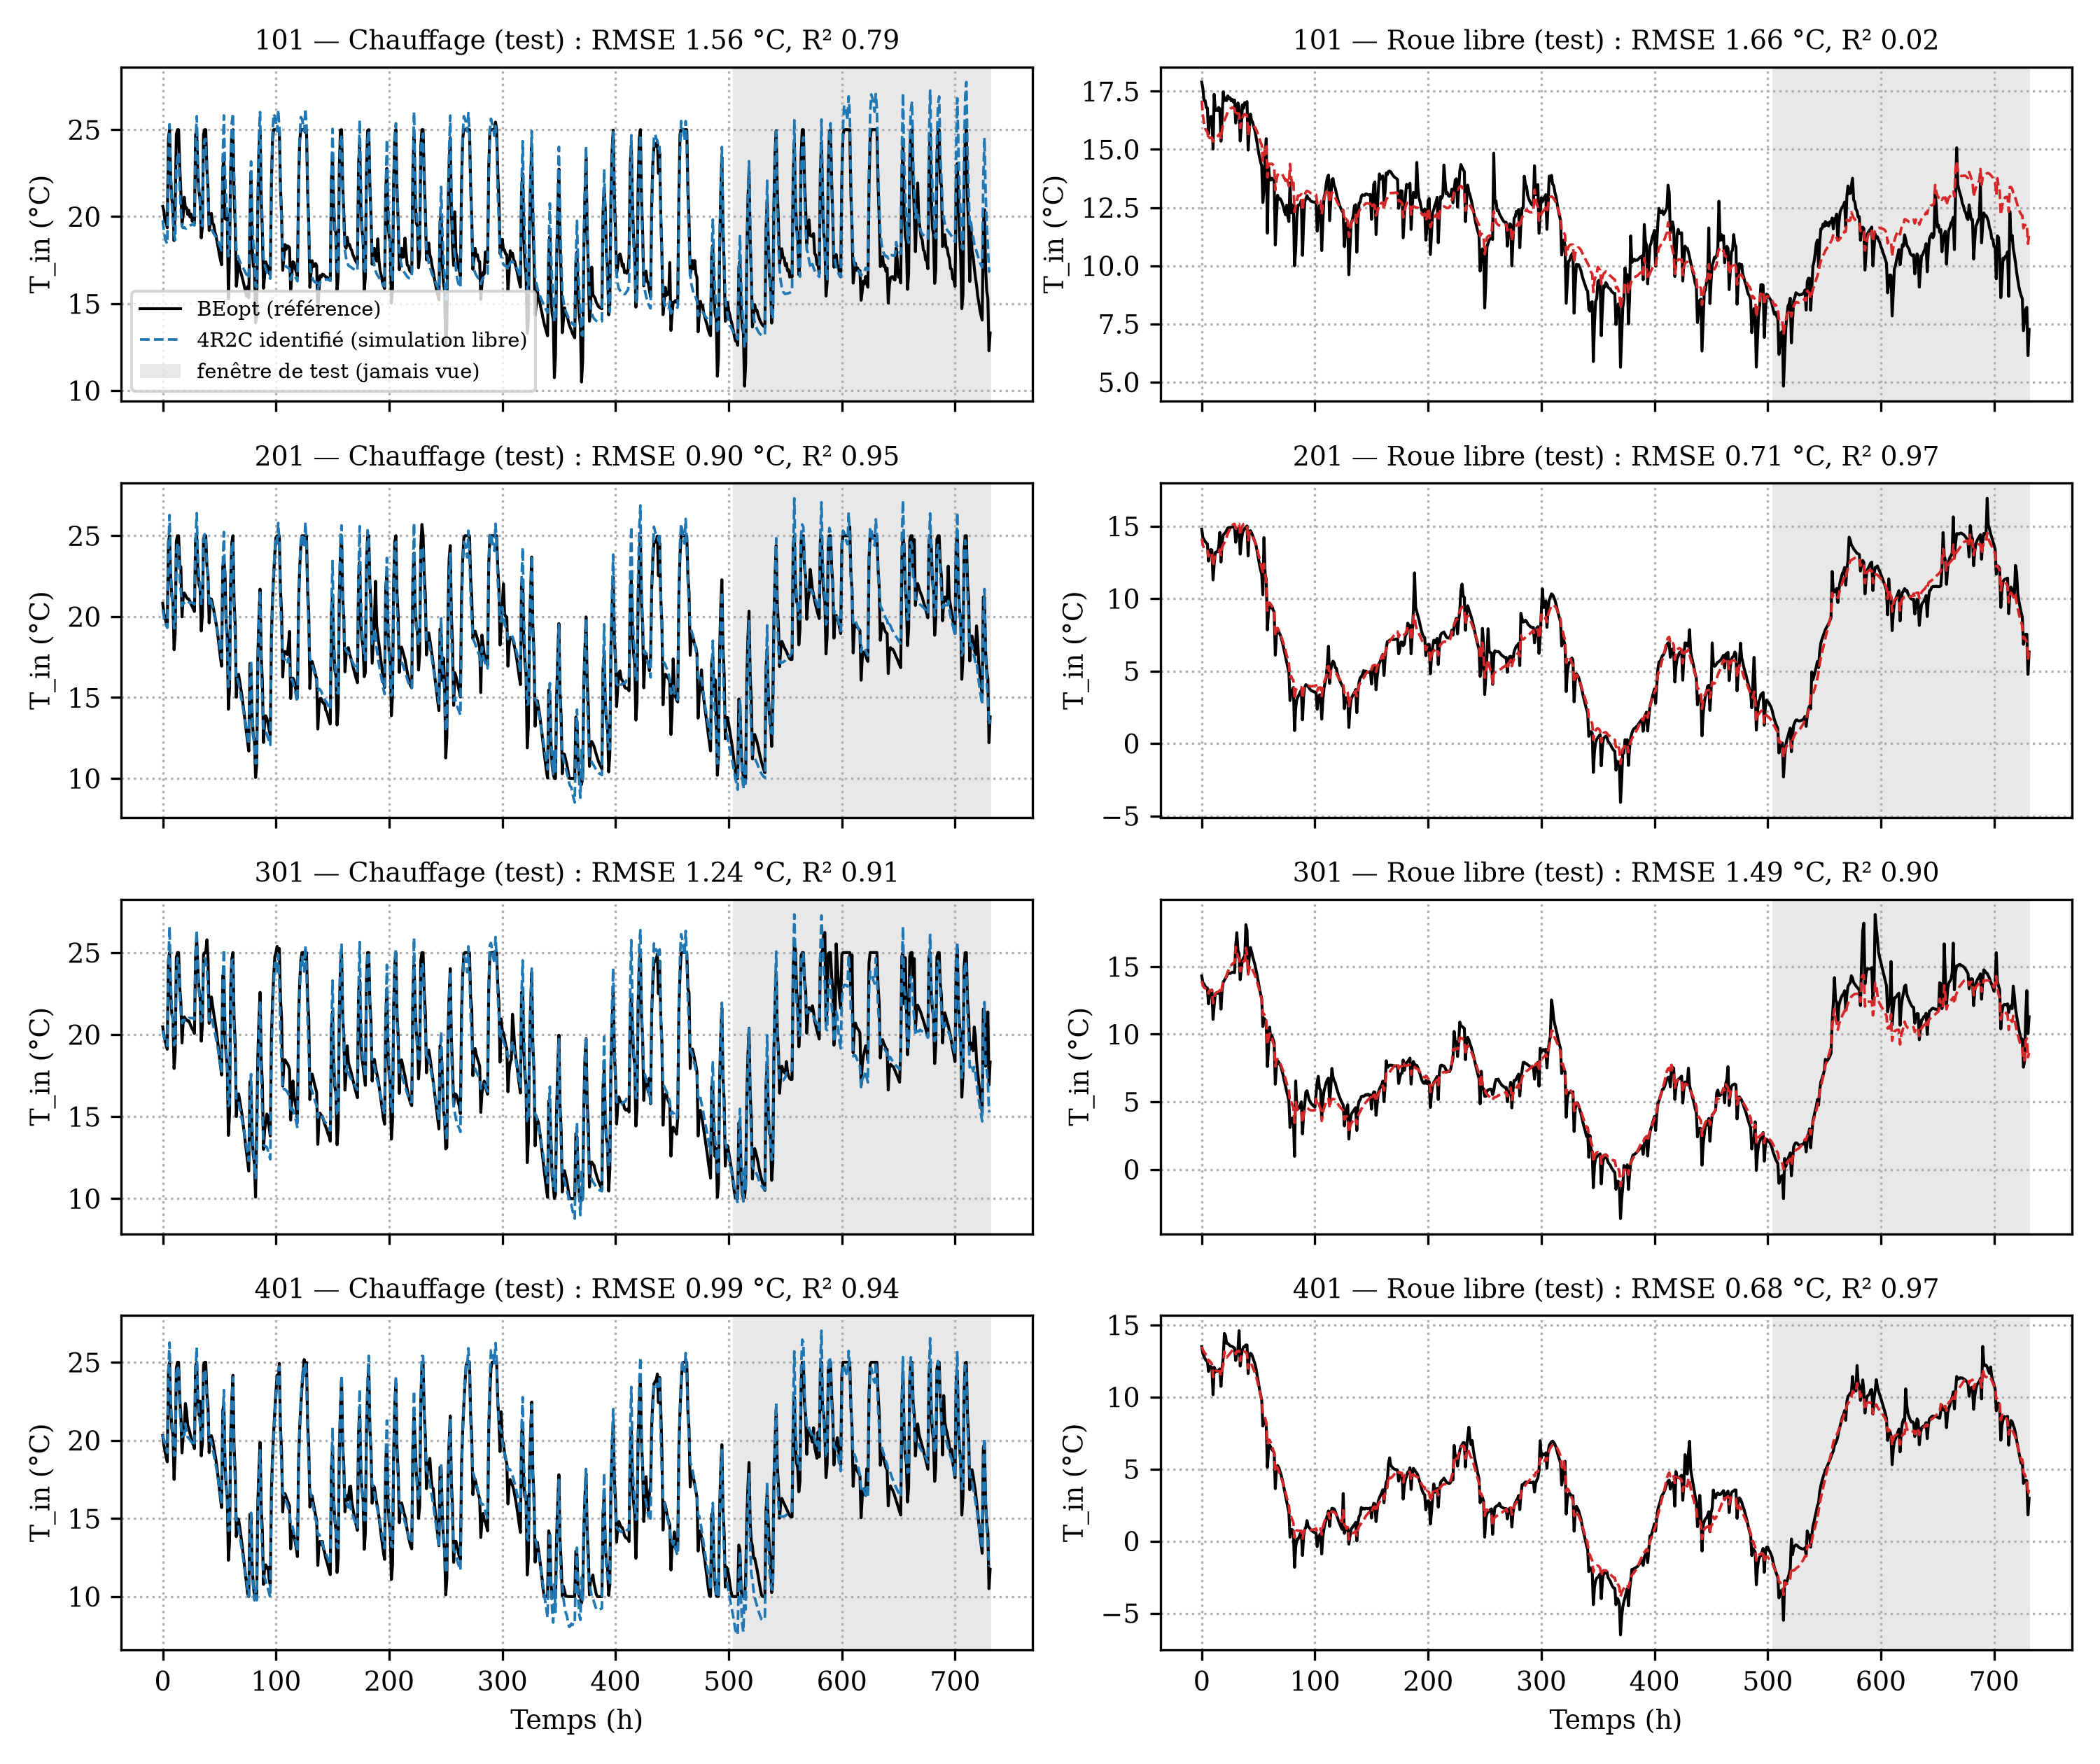

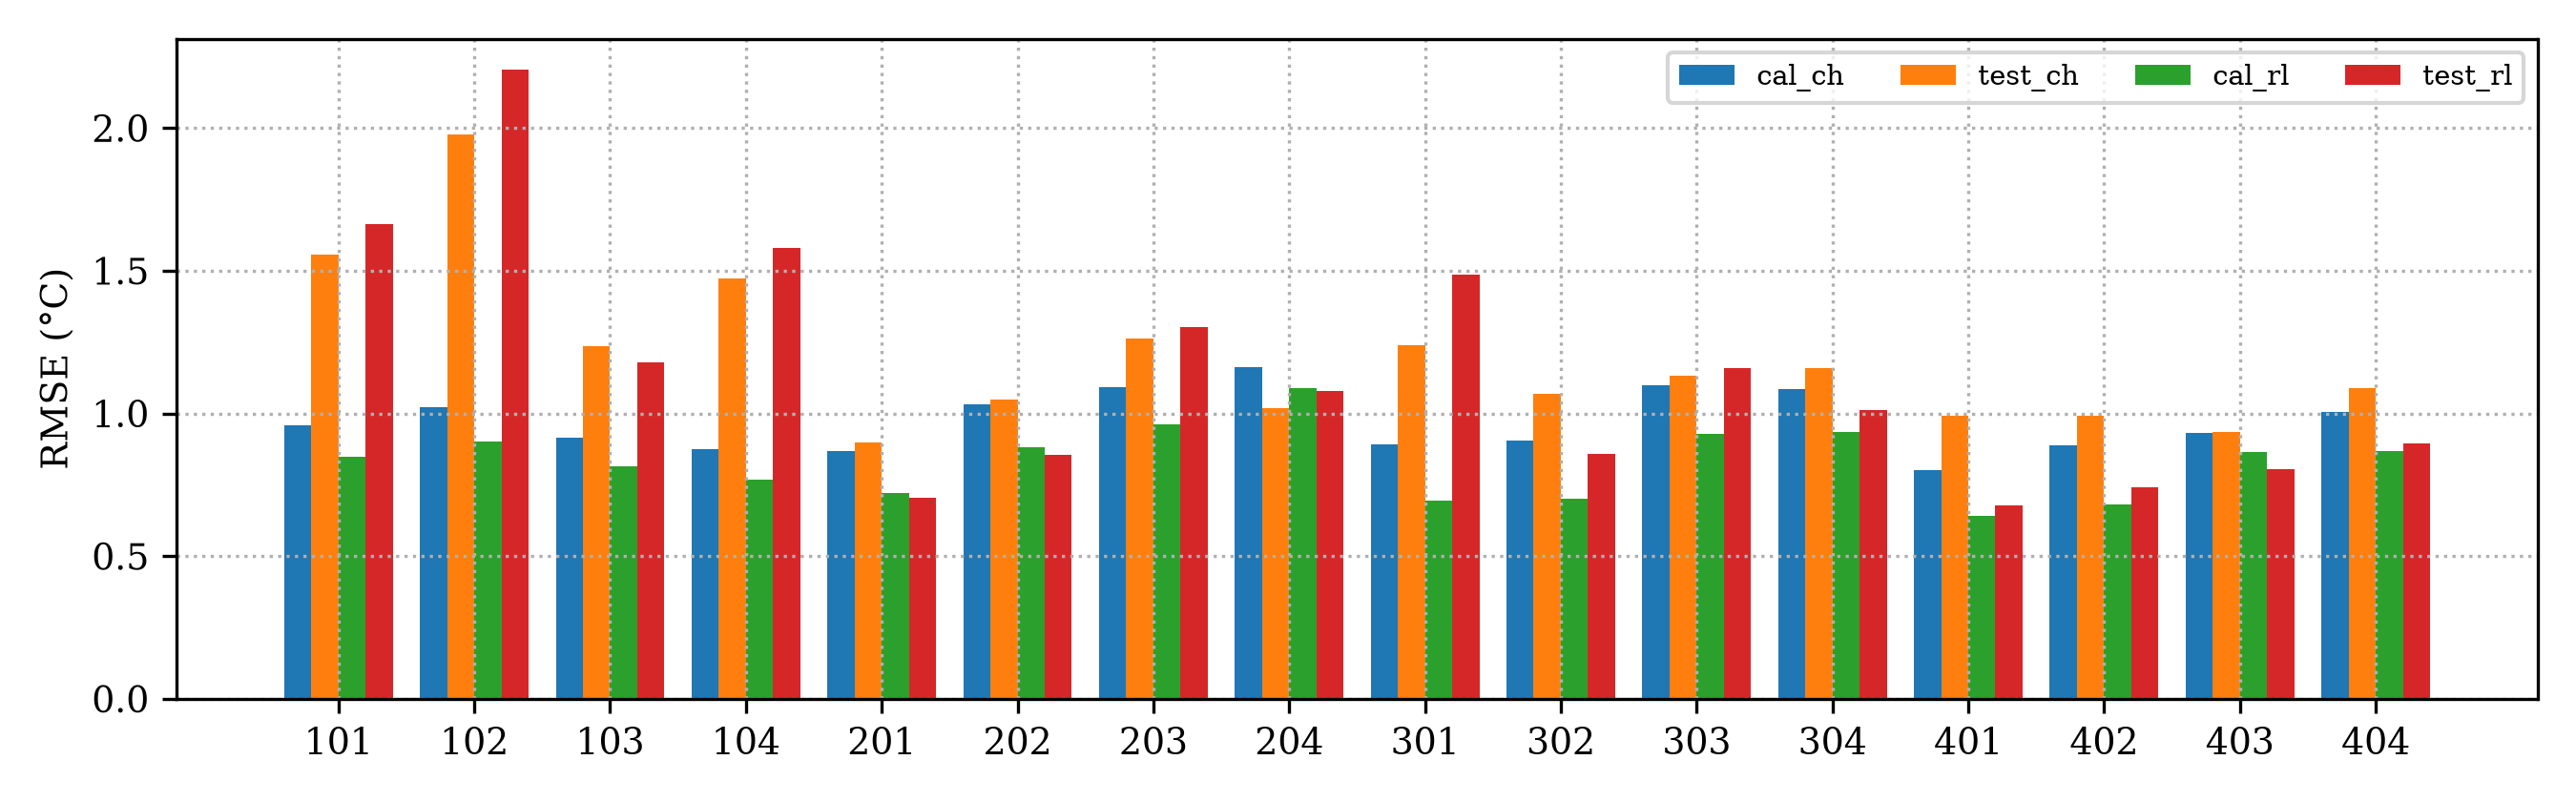

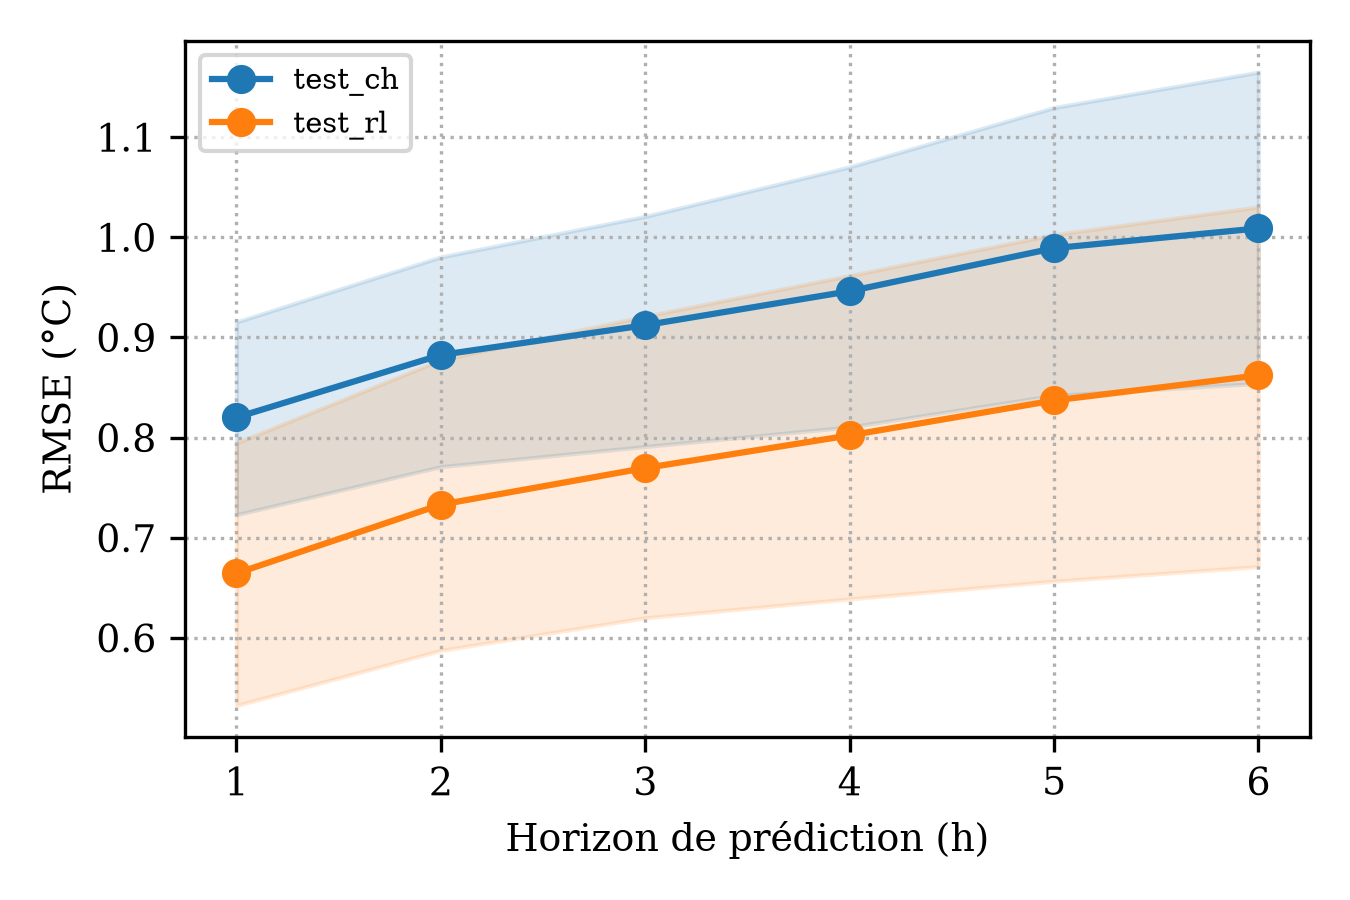

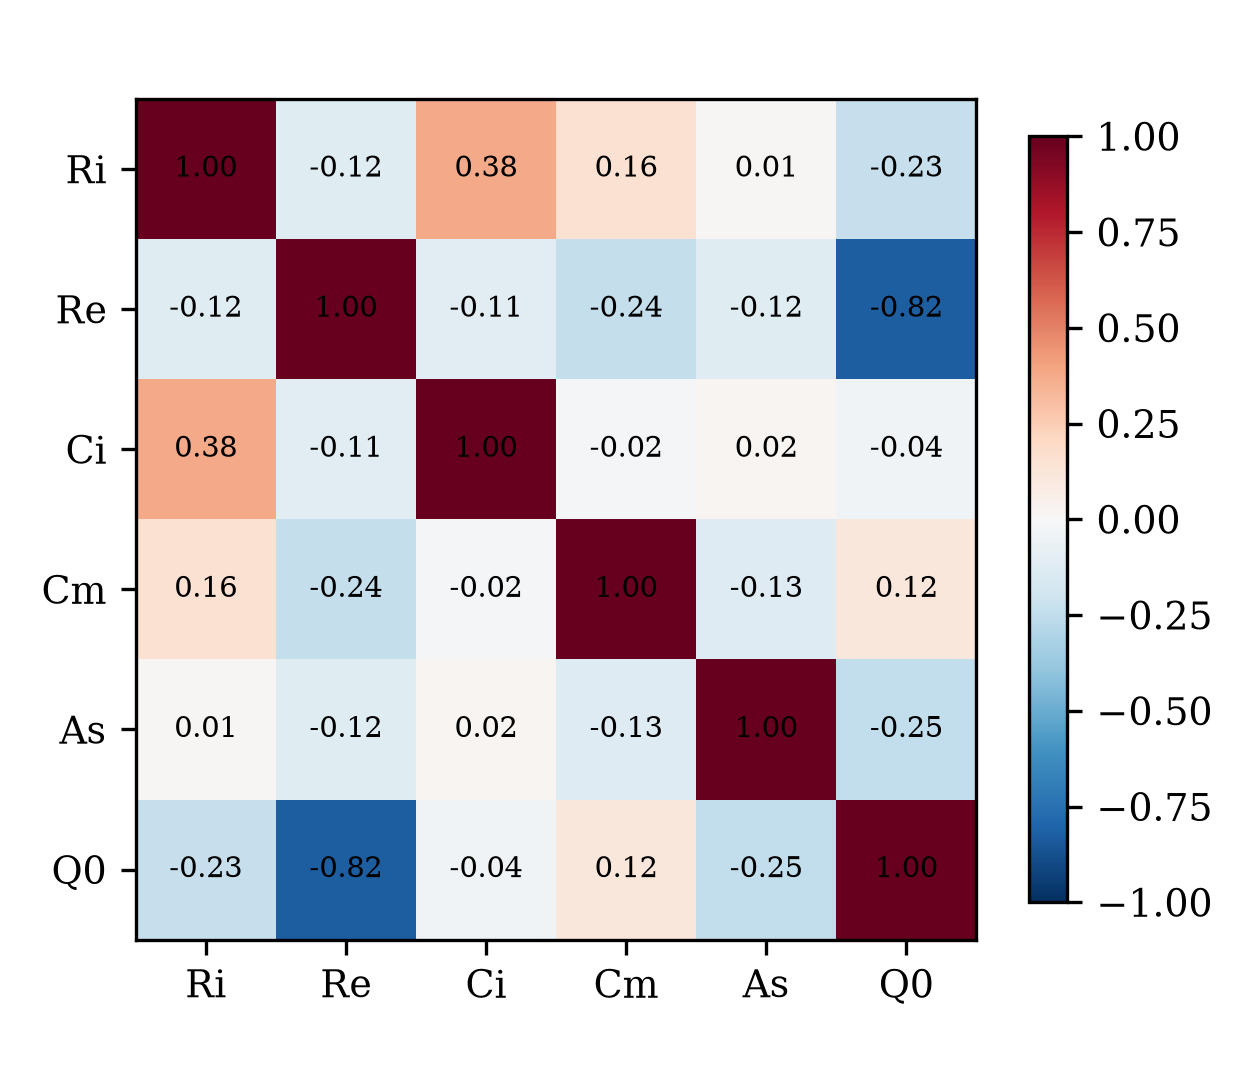

In [14]:
from IPython.display import Image, display
for f in ["fig1_simulation_libre", "fig2_rmse_par_logement", "fig3_erreur_horizon", "fig4_correlations"]:
    display(Image(f"{CONFIG['dossier_sorties']}/ekf4r2c_{f}.png", width=900))